<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab9_2_CNN_Peru_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neuronales Convolucionales (CNN)
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [Deep Learning book (Goodfellow et al.)](https://www.deeplearningbook.org/) | [Keras](https://keras.io/) | FWE458 Lec23 (CNN)

> ⚡ **Versión rápida:** este lab **no descarga ningún dataset**. Los parches satelitales se generan en segundos dentro del notebook y la CNN se entrena en menos de 1 minuto en CPU (Colab o local).

---

### Objetivos de aprendizaje

1. Distinguir entre características diseñadas manualmente y características aprendidas.
2. Representar imágenes y datos multicanal como tensores.
3. Describir las operaciones clave de las CNN: convolución, pooling y ReLU.
4. Explicar el patrón encoder-decoder que subyace a las arquitecturas CNN.
5. Construir y entrenar una CNN en Keras para clasificar parches satelitales de cobertura del suelo.
6. Comparar una CNN con un Random Forest sobre características espectrales y entender **cuándo** el patrón espacial importa.

In [ ]:
# Instalar TensorFlow si el entorno no lo trae (p. ej. algunos runtimes de Google Colab)
# La primera vez tarda ~1–2 minutos; después solo se importa.
import importlib.util, subprocess, sys

if importlib.util.find_spec('tensorflow') is None:
    print('Instalando TensorFlow...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'])

import tensorflow as tf
print(f'TensorFlow {tf.__version__} listo')

## 1. ¿Qué es una Característica?

En todos los Labs anteriores, las **características ya estaban preparadas** para nosotros: NDVI, temperatura, precipitación, bandas espectrales. Alguien decidió qué medir, y los números llegaron en una hoja de cálculo.

Pero, ¿qué pasa con los datos no estructurados?

### Ejemplo: Clasificar imágenes de drones del SERNANP

El SERNANP usa drones para monitorear la deforestación en el Manu. Quieres clasificar cada imagen como "bosque intacto", "bosque degradado" o "deforestado".

¿Puedes escribir una fórmula para "bosque intacto"?
- "¿Blobs verdes?" → falla si hay sombras o luz directa
- "¿Forma de copa arbórea?" → ¿cómo codificas "forma" como número?

No hay un vector de características limpio que capture "bosque-ness". Aquí es donde las CNN son poderosas.

### Características diseñadas vs. características aprendidas

| Enfoque | Las características vienen de | Ejemplo |
|---------|------------------------------|--------|
| ML clásico | *Tú* — conocimiento de dominio, prueba y error | Calcular NDVI desde bandas Landsat, luego alimentar a Random Forest |
| Deep Learning (CNN) | *La red* — aprendidas automáticamente durante el entrenamiento | Alimentar bandas brutas a una CNN; descubre que las combinaciones "NDVI-like" son útiles |

Las CNN fusionan extracción de características y modelado — optimizados juntos de extremo a extremo.

## 2. Tensores: Cómo Representamos los Datos

Las CNN trabajan con **tensores** — la generalización de escalares, vectores y matrices.

| Nombre | Dimensiones | Ejemplo |
|--------|-------------|---------|
| Escalar | 0D | Temperatura: `25.3` |
| Vector | 1D | Características de una estación: `[temp, precip, humedad]` |
| Matriz | 2D | Dataset tabular: filas×columnas |
| **Tensor 3D** | **3D** | **Una imagen: alto×ancho×canales** |
| Tensor 4D | 4D | Lote de imágenes: lote×alto×ancho×canales |

### Imágenes satelitales como tensores

Un parche Landsat de 64×64 pixeles con 6 bandas espectrales = tensor de forma `(64, 64, 6)`

Esto contiene $64 \times 64 \times 6 = 24{,}576$ números — estos son los valores brutos que la CNN procesará.

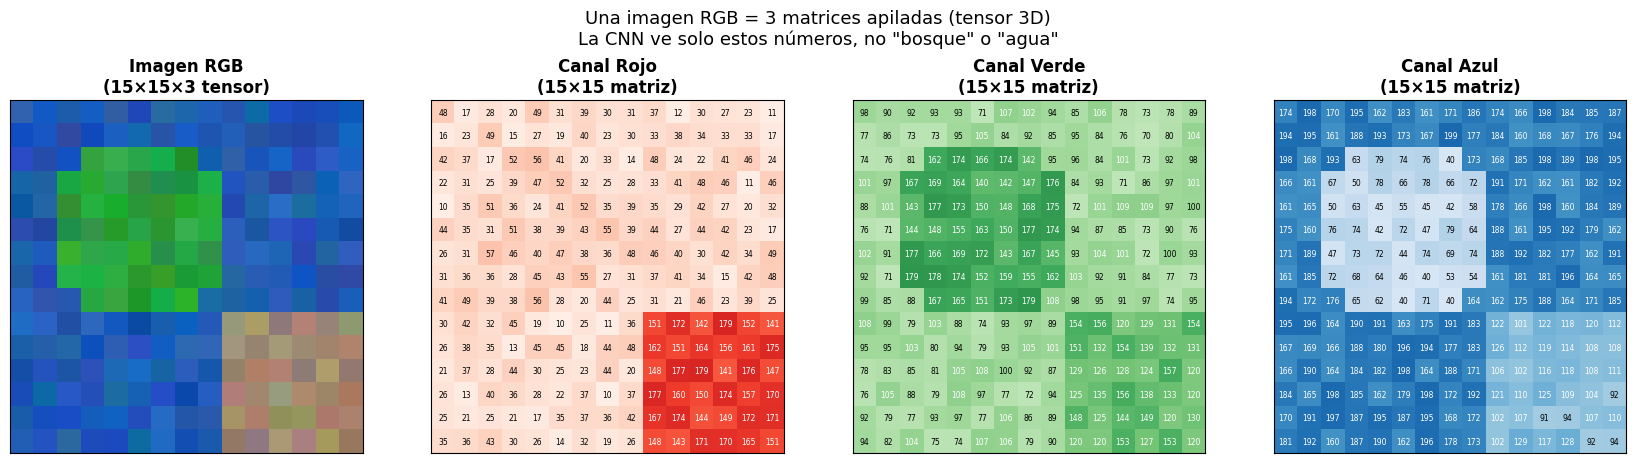

Forma del tensor de imagen: (15, 15, 3)  (alto, ancho, canales)
Total de números: 675 valores de 0-255


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Demostrar cómo una imagen de cobertura del suelo es un tensor 3D
np.random.seed(42)

# Simular una imagen RGB pequeña de una parcela en la Amazonia
img = np.zeros((15, 15, 3), dtype=np.uint8)
# Bosque verde
for i in range(15):
    for j in range(15):
        if (i-5)**2 + (j-5)**2 < 15:
            img[i,j] = [40, 160, 60]   # verde bosque
        elif i > 8 and j > 8:
            img[i,j] = [160, 140, 110]  # marrón suelo/quemado
        else:
            img[i,j] = [30, 90, 180]    # azul agua

# Añadir ruido
img = np.clip(img + np.random.randint(-20, 20, img.shape), 0, 255).astype(np.uint8)

fig, ejes = plt.subplots(1, 4, figsize=(17, 4.5))

ejes[0].imshow(img)
ejes[0].set_title('Imagen RGB\n(15×15×3 tensor)', fontweight='bold')
ejes[0].set_xticks([]); ejes[0].set_yticks([])

nombres_canal = ['Canal Rojo', 'Canal Verde', 'Canal Azul']
cmaps_canal   = ['Reds', 'Greens', 'Blues']
for i, (nombre, cmap) in enumerate(zip(nombres_canal, cmaps_canal)):
    ax = ejes[i+1]
    ax.imshow(img[:, :, i], cmap=cmap, vmin=0, vmax=255)
    for r in range(15):
        for c in range(15):
            ax.text(c, r, str(img[r, c, i]), ha='center', va='center',
                    fontsize=5.5, color='white' if img[r,c,i] > 100 else 'black')
    ax.set_title(f'{nombre}\n(15×15 matriz)', fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Una imagen RGB = 3 matrices apiladas (tensor 3D)\n'
             'La CNN ve solo estos números, no "bosque" o "agua"',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Forma del tensor de imagen: {img.shape}  (alto, ancho, canales)")
print(f"Total de números: {img.size:,} valores de 0-255")

## 3. Redes Neuronales Profundas como Jerarquías de Representación

Las CNN aprenden características de forma jerárquica:

| Capa | Escala | Qué detecta en imágenes satelitales peruanas |
|------|--------|-----------------------------------------|
| Capa 1 | Píxeles individuales | Diferencias de reflectancia, bordes |
| Capa 2 | Parches ~10m | Rugosidad del dosel, suavidad del agua |
| Capa 3 | Parches ~30m | Copas de árboles, surcos agrícolas, bordes de edificios |
| Capas profundas | Región completa | Clase de cobertura, tipo de hábitat |

**Nadie programa estas características — la red las descubre de los datos.**

## 4. El Patrón Encoder-Decoder

Casi todas las arquitecturas CNN pueden entenderse como:

```
Imagen de entrada → [ENCODER] → representación compacta → [DECODER] → salida
  (alto-dim)        (capas conv)    (vector latente)       (capas densas)  (clasificación)
```

El **encoder** comprime la imagen en una representación abstracta. El **decoder** usa esa representación para producir la salida deseada.

## 5. La Operación de Convolución

Una **convolución** es una ventana deslizante pequeña — llamada **filtro** o **kernel** — que se mueve por la imagen. En cada posición, calcula la suma ponderada de los píxeles que cubre.

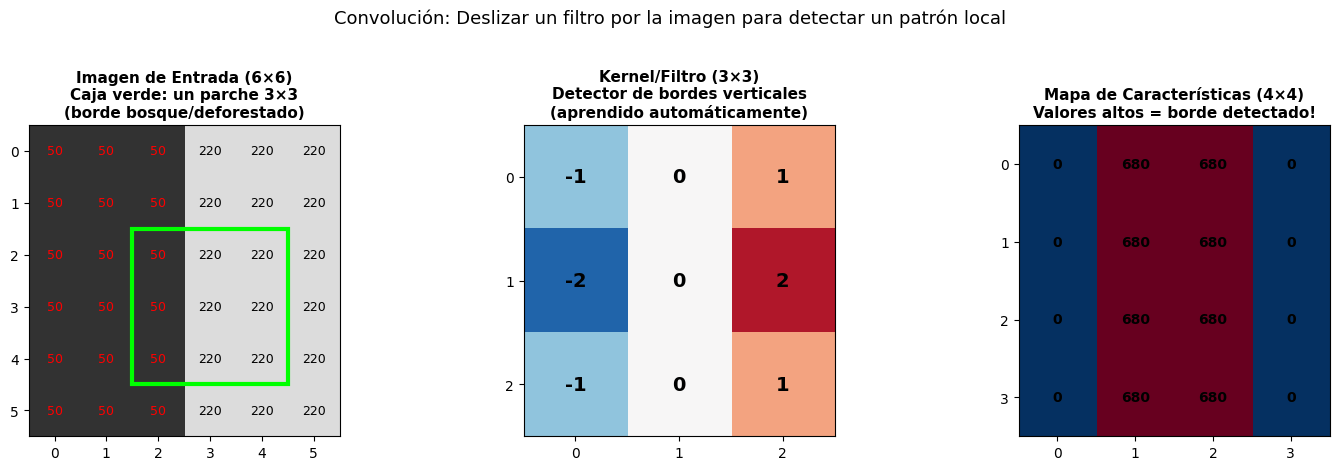

El mapa de características muestra DÓNDE el filtro respondió fuertemente.
La columna 3 (borde bosque/deforestación) tiene los valores más altos.

En una CNN REAL, los valores del filtro se APRENDEN automáticamente
a través del entrenamiento (retropropagación).


In [ ]:
# Demostrar la operación de convolución con un detector de bordes
from matplotlib.patches import Rectangle

# Imagen 6x6 con un borde vertical claro (simula borde bosque/deforestación)
imagen_borde = np.array([
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
], dtype=float)

# Kernel detector de bordes verticales (tipo Sobel)
kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)

# Convolución manual
def conv2d(img, k):
    kh, kw = k.shape
    ih, iw = img.shape
    out = np.zeros((ih - kh + 1, iw - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = (img[i:i+kh, j:j+kw] * k).sum()
    return out

mapa_caracteristicas = conv2d(imagen_borde, kernel)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# Imagen de entrada
ejes[0].imshow(imagen_borde, cmap='gray', vmin=0, vmax=255)
for i in range(6):
    for j in range(6):
        ejes[0].text(j, i, int(imagen_borde[i,j]), ha='center', va='center',
                     color='red' if imagen_borde[i,j] < 130 else 'black', fontsize=9)
rect = Rectangle((1.5, 1.5), 3, 3, fill=False, edgecolor='lime', linewidth=3)
ejes[0].add_patch(rect)
ejes[0].set_title('Imagen de Entrada (6×6)\nCaja verde: un parche 3×3\n(borde bosque/deforestado)',
                   fontsize=11, fontweight='bold')
ejes[0].set_xticks(range(6)); ejes[0].set_yticks(range(6))

# Kernel
ejes[1].imshow(kernel, cmap='RdBu_r', vmin=-2.5, vmax=2.5)
for i in range(3):
    for j in range(3):
        ejes[1].text(j, i, int(kernel[i,j]), ha='center', va='center',
                     fontsize=14, fontweight='bold')
ejes[1].set_title('Kernel/Filtro (3×3)\nDetector de bordes verticales\n(aprendido automáticamente)',
                   fontsize=11, fontweight='bold')
ejes[1].set_xticks(range(3)); ejes[1].set_yticks(range(3))

# Mapa de características
ejes[2].imshow(mapa_caracteristicas, cmap='RdBu_r')
for i in range(mapa_caracteristicas.shape[0]):
    for j in range(mapa_caracteristicas.shape[1]):
        ejes[2].text(j, i, f'{int(mapa_caracteristicas[i,j])}',
                     ha='center', va='center', fontsize=10, fontweight='bold')
ejes[2].set_title(f'Mapa de Características ({mapa_caracteristicas.shape[0]}×{mapa_caracteristicas.shape[1]})\n'
                   'Valores altos = borde detectado!', fontsize=11, fontweight='bold')
ejes[2].set_xticks(range(mapa_caracteristicas.shape[1]))
ejes[2].set_yticks(range(mapa_caracteristicas.shape[0]))

plt.suptitle('Convolución: Deslizar un filtro por la imagen para detectar un patrón local',
             fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

print("El mapa de características muestra DÓNDE el filtro respondió fuertemente.")
print("La columna 3 (borde bosque/deforestación) tiene los valores más altos.")
print("\nEn una CNN REAL, los valores del filtro se APRENDEN automáticamente")
print("a través del entrenamiento (retropropagación).")

### Varios filtros = varios mapas de características

Una capa convolucional no usa un solo filtro sino muchos (32, 64...). Cada filtro produce un **mapa de características** que indica *dónde* apareció su patrón. Aquí usamos filtros diseñados a mano; en una CNN real, **los pesos de los filtros se aprenden** por retropropagación.

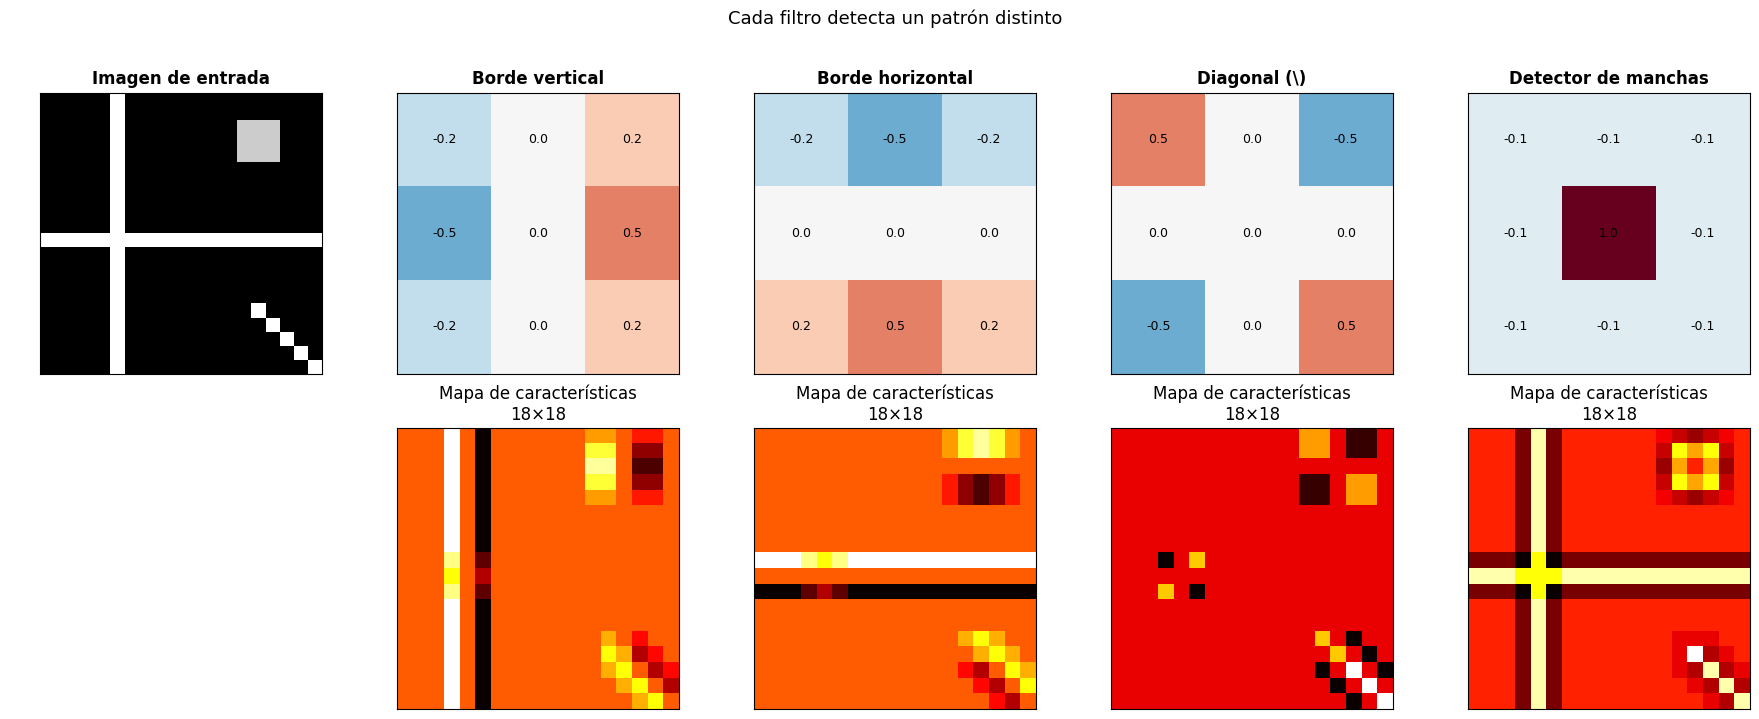

In [ ]:
# Aplicar 4 filtros distintos a una imagen sintética (bordes de parcelas, un río, un claro)
imagen = np.zeros((20, 20))
imagen[:, 5] = 1.0                 # línea vertical (lindero de parcela)
imagen[10, :] = 1.0                # línea horizontal (camino)
for i in range(5):
    imagen[15+i, 15+i] = 1.0       # diagonal (cauce)
imagen[2:5, 14:17] = 0.8           # mancha (claro en el bosque)

filtros = {
    'Borde vertical':   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]) / 4,
    'Borde horizontal': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]) / 4,
    'Diagonal (\\)':    np.array([[1, 0, -1], [0, 0, 0], [-1, 0, 1]]) / 2,
    'Detector de manchas': np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]]) / 8,
}

fig, ejes = plt.subplots(2, 5, figsize=(18, 7))
ejes[0, 0].imshow(imagen, cmap='gray')
ejes[0, 0].set_title('Imagen de entrada', fontweight='bold')
ejes[0, 0].set_xticks([]); ejes[0, 0].set_yticks([])
ejes[1, 0].axis('off')

for col, (nombre, k) in enumerate(filtros.items(), start=1):
    ejes[0, col].imshow(k, cmap='RdBu_r', vmin=-1, vmax=1)
    for i in range(3):
        for j in range(3):
            ejes[0, col].text(j, i, f'{k[i, j]:.1f}', ha='center', va='center', fontsize=9)
    ejes[0, col].set_title(nombre, fontweight='bold')
    ejes[0, col].set_xticks([]); ejes[0, col].set_yticks([])
    fmap = conv2d(imagen, k)
    ejes[1, col].imshow(fmap, cmap='hot')
    ejes[1, col].set_title(f'Mapa de características\n{fmap.shape[0]}×{fmap.shape[1]}')
    ejes[1, col].set_xticks([]); ejes[1, col].set_yticks([])

plt.suptitle('Cada filtro detecta un patrón distinto', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Max Pooling: Reducir el Tamaño Espacial

Después de una capa convolucional, el **max pooling** reduce las dimensiones espaciales seleccionando el valor máximo en cada bloque 2×2:
- **Reduce el cómputo** en un factor de 4×
- **Proporciona invarianza a la translación** — pequeños desplazamientos en la entrada no cambian mucho la salida
- **Conserva la señal más fuerte** de cada bloque

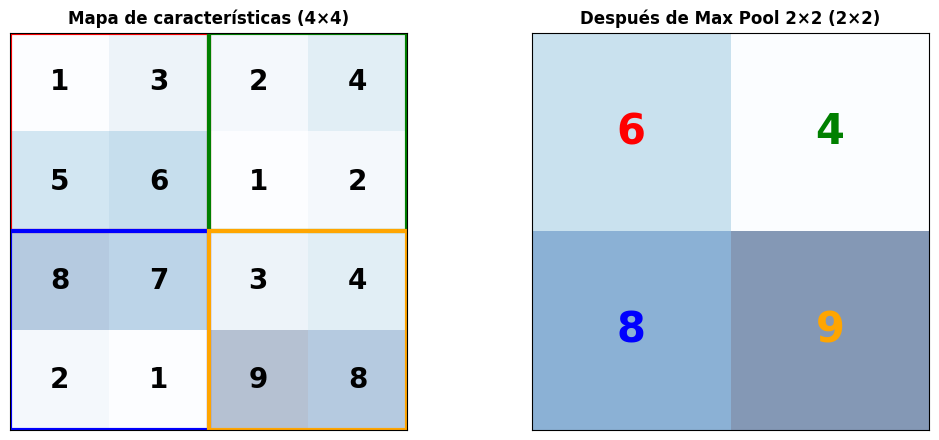

In [ ]:
# Max pooling 2×2 sobre un mapa de características 4×4
fmap = np.array([[1, 3, 2, 4],
                 [5, 6, 1, 2],
                 [8, 7, 3, 4],
                 [2, 1, 9, 8]], dtype=float)
pooled = fmap.reshape(2, 2, 2, 2).max(axis=(1, 3))

colores = ['red', 'green', 'blue', 'orange']
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
ejes[0].imshow(fmap, cmap='Blues', alpha=0.3)
for i in range(4):
    for j in range(4):
        ejes[0].text(j, i, int(fmap[i, j]), ha='center', va='center', fontsize=20, fontweight='bold')
for b in range(4):
    bi, bj = divmod(b, 2)
    ejes[0].add_patch(Rectangle((bj*2 - 0.5, bi*2 - 0.5), 2, 2, fill=False,
                                edgecolor=colores[b], linewidth=3))
ejes[0].set_title('Mapa de características (4×4)', fontweight='bold')

ejes[1].imshow(pooled, cmap='Blues', alpha=0.5)
for b in range(4):
    bi, bj = divmod(b, 2)
    ejes[1].text(bj, bi, int(pooled[bi, bj]), ha='center', va='center',
                 fontsize=30, fontweight='bold', color=colores[b])
ejes[1].set_title('Después de Max Pool 2×2 (2×2)', fontweight='bold')
for ax in ejes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### ReLU: la no linealidad

Entre convoluciones se aplica $\text{ReLU}(x) = \max(0, x)$: los valores negativos pasan a cero. Sin esta no linealidad, apilar convoluciones equivaldría a una sola operación lineal.

### Juntando todo

```
Parche (32×32×4)
  → [Conv(16) → ReLU → Pool]   # Bloque 1: bordes, contrastes de reflectancia
  → [Conv(32) → ReLU → Pool]   # Bloque 2: texturas (surcos, copas, manzanas)
  → Flatten                     # ENCODER termina aquí: vector de características
  → [Dense(64) → ReLU]          # DECODER: clasificación
  → Dense(5) → Softmax          # Probabilidad de cada clase de cobertura
```

## 6. Datos: Parches Satelitales de Cobertura del Suelo en el Perú

En lugar de descargar un dataset grande (CIFAR-10 pesa ~170 MB y tiene 50 000 imágenes), **simulamos parches tipo Sentinel-2** directamente en el notebook:

- **4 bandas:** Azul, Verde, Rojo, NIR (10 m de resolución) → tensor `(32, 32, 4)` = parche de 320 m × 320 m
- **5 clases** con firmas espectrales realistas y **patrones espaciales** típicos del Perú:

| Clase | Ejemplo en el Perú | Patrón espacial |
|---|---|---|
| 0 · Bosque intacto | Parque Nacional del Manu | Dosel continuo con textura de copas |
| 1 · Bosque degradado | Madre de Dios (claros por minería/tala) | Manchas **irregulares** de suelo desnudo |
| 2 · Agricultura | Valle de Ica, Chavimochic | **Franjas paralelas** de cultivo y suelo |
| 3 · Agua | Lago Titicaca, río Ucayali | Superficie lisa, NIR casi cero |
| 4 · Urbano | Lima Metropolitana | **Cuadrícula** de manzanas y calles |

🔑 **Truco del diseño:** *bosque degradado* y *agricultura* son mezclas de **las mismas dos firmas** (vegetación + suelo) en la **misma proporción**. Espectralmente son casi idénticos; solo se distinguen por la **forma** en que se distribuyen los píxeles. ¿Podrá un modelo clásico separarlos? ¿Y una CNN?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

rng = np.random.default_rng(42)
TAM = 32
BANDAS = ['Azul', 'Verde', 'Rojo', 'NIR']
CLASES = ['Bosque intacto', 'Bosque degradado', 'Agricultura', 'Agua', 'Urbano']

# Firmas espectrales aproximadas (reflectancia 0-1) para B, G, R, NIR
FIRMAS = {
    'vegetacion': np.array([0.04, 0.07, 0.04, 0.40]),
    'suelo':      np.array([0.12, 0.16, 0.20, 0.26]),
    'agua':       np.array([0.06, 0.05, 0.03, 0.01]),
    'techo':      np.array([0.22, 0.22, 0.24, 0.28]),
    'asfalto':    np.array([0.08, 0.08, 0.09, 0.11]),
}
yy, xx = np.mgrid[:TAM, :TAM]

def campo_suave(sigma):
    # Campo aleatorio espacialmente correlacionado, escalado a [0, 1]
    c = gaussian_filter(rng.normal(size=(TAM, TAM)), sigma)
    return (c - c.min()) / (c.max() - c.min() + 1e-9)

def mezclar(mascara, a, b):
    # Píxeles con mascara=1 toman la firma a; el resto, la firma b
    m = mascara[..., None].astype('float32')
    return m * FIRMAS[a] + (1 - m) * FIRMAS[b]

def crear_parche(clase):
    fraccion = rng.uniform(0.35, 0.65)          # % de vegetación (clases 1 y 2)
    if clase == 0:    # Bosque intacto: dosel continuo con textura de copas
        copas = campo_suave(1.0)
        img = FIRMAS['vegetacion'] * (0.7 + 0.6 * copas[..., None])
    elif clase == 1:  # Bosque degradado: claros irregulares de suelo desnudo
        campo = campo_suave(3.0)
        img = mezclar(campo > np.quantile(campo, 1 - fraccion), 'vegetacion', 'suelo')
    elif clase == 2:  # Agricultura: surcos/parcelas en franjas paralelas
        periodo, angulo = rng.integers(5, 10), rng.uniform(0, np.pi)
        onda = (xx * np.cos(angulo) + yy * np.sin(angulo)) / periodo + rng.uniform()
        img = mezclar((onda % 1) < fraccion, 'vegetacion', 'suelo')
    elif clase == 3:  # Agua: superficie lisa con leve turbidez
        img = FIRMAS['agua'] * (0.8 + 0.4 * campo_suave(6.0)[..., None])
    else:             # Urbano: manzanas (techos) separadas por calles (asfalto)
        manzana = rng.integers(6, 10)
        dx, dy = rng.integers(0, manzana, 2)
        techos = ((xx + dx) % manzana >= 2) & ((yy + dy) % manzana >= 2)
        img = mezclar(techos, 'techo', 'asfalto')
    img = img * rng.uniform(0.85, 1.15)          # variación de iluminación
    img = img + rng.normal(0, 0.015, img.shape)  # ruido del sensor
    return np.clip(img, 0, 1).astype('float32')

n_por_clase = 400
X_parches = np.stack([crear_parche(c) for c in range(len(CLASES)) for _ in range(n_por_clase)])
y_parches = np.repeat(np.arange(len(CLASES)), n_por_clase)

print(f"Tensor de parches: {X_parches.shape}  → (muestras, alto, ancho, bandas)")
print(f"Memoria: {X_parches.nbytes / 1e6:.1f} MB  (CIFAR-10 completo: ~600 MB en float32)")

Tensor de parches: (2000, 32, 32, 4)  → (muestras, alto, ancho, bandas)
Memoria: 32.8 MB  (CIFAR-10 completo: ~600 MB en float32)


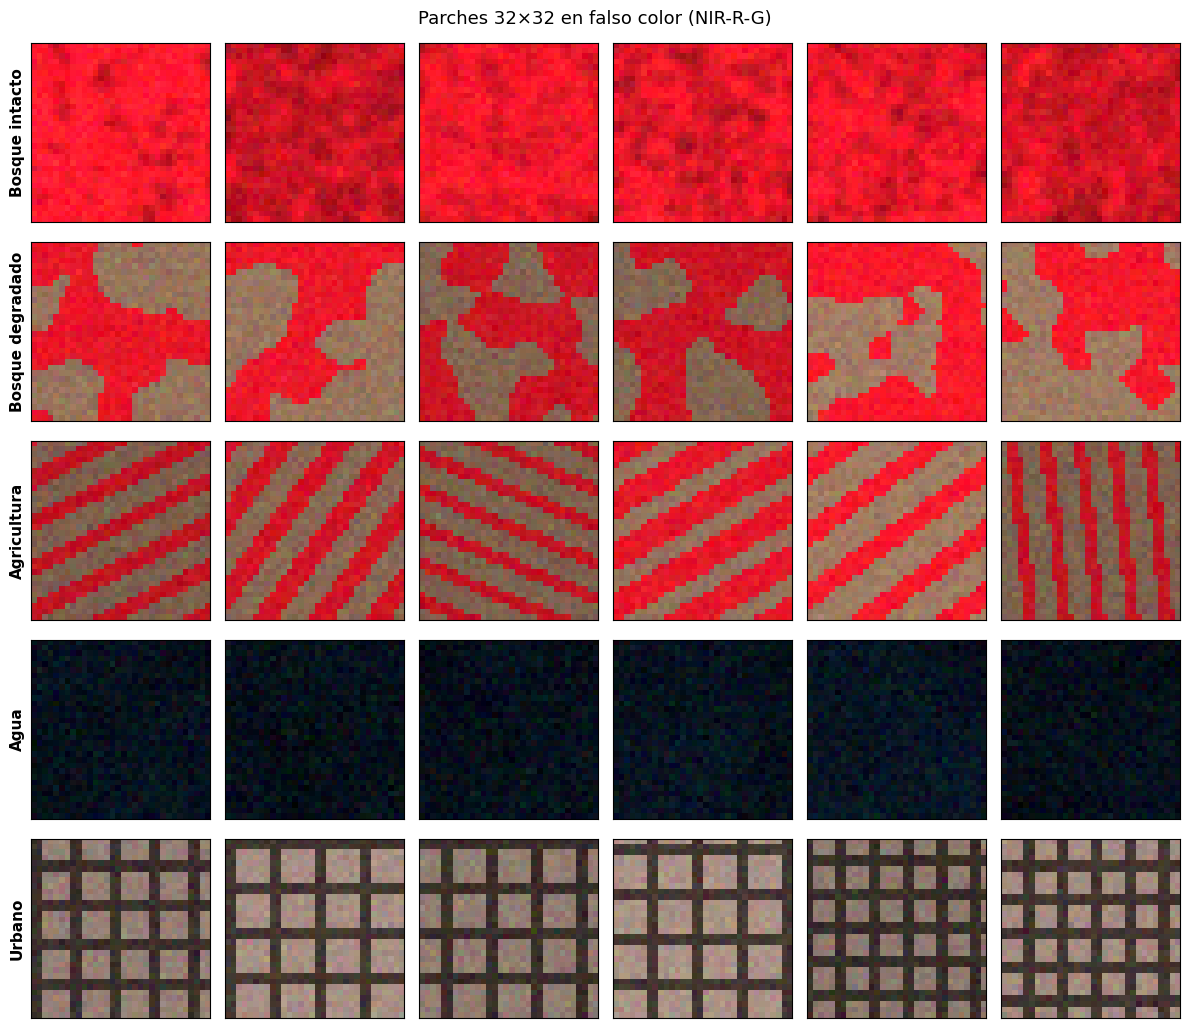

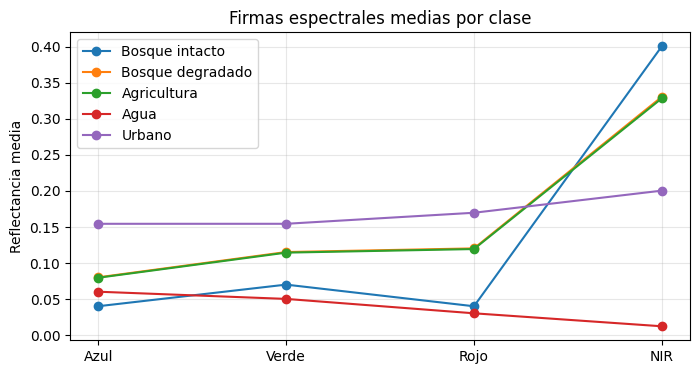

In [ ]:
# Visualizar en falso color (NIR-Rojo-Verde): la vegetación aparece en rojo
def falso_color(p):
    return np.clip(p[..., [3, 2, 1]] / 0.45, 0, 1)

fig, ejes = plt.subplots(len(CLASES), 6, figsize=(12, 10.5))
for c, nombre in enumerate(CLASES):
    idx = np.where(y_parches == c)[0][:6]
    for j, i in enumerate(idx):
        ejes[c, j].imshow(falso_color(X_parches[i]))
        ejes[c, j].set_xticks([]); ejes[c, j].set_yticks([])
    ejes[c, 0].set_ylabel(nombre, fontsize=11, fontweight='bold')
plt.suptitle('Parches 32×32 en falso color (NIR-R-G)', fontsize=13)
plt.tight_layout()
plt.show()

# Firma espectral media por clase
fig, ax = plt.subplots(figsize=(8, 4))
for c, nombre in enumerate(CLASES):
    ax.plot(BANDAS, X_parches[y_parches == c].mean(axis=(0, 1, 2)), 'o-', label=nombre)
ax.set_ylabel('Reflectancia media'); ax.set_title('Firmas espectrales medias por clase')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

👀 Observa el gráfico de firmas: **bosque degradado** y **agricultura** se superponen casi por completo. A simple vista, sin embargo, los parches son muy distintos: manchas vs. franjas.

## 7. Línea Base: Random Forest con Características Diseñadas

Primero hacemos lo que haríamos con ML clásico (Lab 8): **diseñar características a mano** (media y desviación estándar de cada banda = 8 números por parche) y entrenar un Random Forest.

Exactitud Random Forest (características espectrales): 79.0%


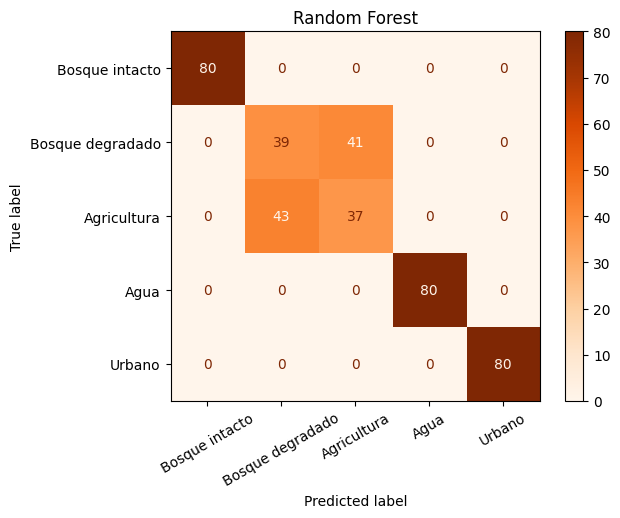

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

X_tr, X_te, y_tr, y_te = train_test_split(X_parches, y_parches, test_size=0.2,
                                          stratify=y_parches, random_state=42)

def caracteristicas_espectrales(X):
    # 8 características por parche: media y desviación de cada banda
    return np.hstack([X.mean(axis=(1, 2)), X.std(axis=(1, 2))])

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(caracteristicas_espectrales(X_tr), y_tr)
pred_rf = rf.predict(caracteristicas_espectrales(X_te))
exactitud_rf = accuracy_score(y_te, pred_rf)
print(f"Exactitud Random Forest (características espectrales): {exactitud_rf:.1%}")

ConfusionMatrixDisplay.from_predictions(y_te, pred_rf, display_labels=CLASES,
                                        xticks_rotation=30, cmap='Oranges')
plt.title('Random Forest')
plt.show()

El RF acierta casi todo **excepto** degradado vs. agricultura, donde adivina al azar (~50%). Las características que elegimos (estadísticas espectrales) **no contienen la información espacial** necesaria. Podríamos inventar más características (textura GLCM, orientación, FFT...), pero eso es justamente la *ingeniería de características* que una CNN hace por nosotros.

## 8. Construir y Entrenar una CNN en Keras

In [ ]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

modelo_cnn = keras.Sequential([
    keras.Input(shape=(TAM, TAM, len(BANDAS))),      # (32, 32, 4)

    # === ENCODER: extracción de características ===
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='conv1'),
    layers.MaxPooling2D((2, 2)),                      # 32×32 → 16×16
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv2'),
    layers.MaxPooling2D((2, 2)),                      # 16×16 → 8×8

    # === DECODER: clasificación ===
    layers.Flatten(),                                 # 8×8×32 → vector de 2048
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(CLASES), activation='softmax'),  # 5 probabilidades de clase
])

modelo_cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 16)     │           592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,693 (533.96 KB)

 Trainable params: 136,693 (533.96 KB)

 Non-trainable params: 0 (0.00 B)

Lee `summary()`: `padding='same'` mantiene 32×32 mientras los canales pasan de 4 bandas a 16 mapas de características; cada MaxPooling reduce a la mitad. Nota que **no usamos StandardScaler**: las reflectancias ya están en [0, 1].

In [ ]:
modelo_cnn.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

parada_temprana = keras.callbacks.EarlyStopping(monitor='val_loss', patience=2,
                                                restore_best_weights=True)
t0 = time.time()
historial = modelo_cnn.fit(X_tr, y_tr,
                           epochs=40, batch_size=32,
                           validation_split=0.15,
                           callbacks=[parada_temprana],
                           verbose=2)
print(f"\nTiempo de entrenamiento: {time.time() - t0:.1f} s")

perdida_cnn, exactitud_cnn = modelo_cnn.evaluate(X_te, y_te, verbose=0)
print(f"Exactitud CNN en prueba:   {exactitud_cnn:.1%}")
print(f"Exactitud RF en prueba:    {exactitud_rf:.1%}")

Epoch 1/40
43/43 - 4s - 89ms/step - accuracy: 0.5963 - loss: 0.9504 - val_accuracy: 0.9125 - val_loss: 0.2896
Epoch 2/40
43/43 - 2s - 38ms/step - accuracy: 0.8868 - loss: 0.2641 - val_accuracy: 0.9750 - val_loss: 0.1285
Epoch 3/40
43/43 - 1s - 30ms/step - accuracy: 0.9654 - loss: 0.1145 - val_accuracy: 1.0000 - val_loss: 0.0343
Epoch 4/40
43/43 - 1s - 30ms/step - accuracy: 0.9912 - loss: 0.0412 - val_accuracy: 1.0000 - val_loss: 0.0106
Epoch 5/40
43/43 - 1s - 29ms/step - accuracy: 0.9963 - loss: 0.0207 - val_accuracy: 1.0000 - val_loss: 0.0059
Epoch 6/40
43/43 - 1s - 29ms/step - accuracy: 0.9978 - loss: 0.0150 - val_accuracy: 1.0000 - val_loss: 0.0072
Epoch 7/40
43/43 - 1s - 28ms/step - accuracy: 0.9963 - loss: 0.0147 - val_accuracy: 1.0000 - val_loss: 0.0056
Epoch 8/40
43/43 - 1s - 29ms/step - accuracy: 0.9971 - loss: 0.0137 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 9/40
43/43 - 1s - 28ms/step - accuracy: 1.0000 - loss: 0.0057 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 10/4

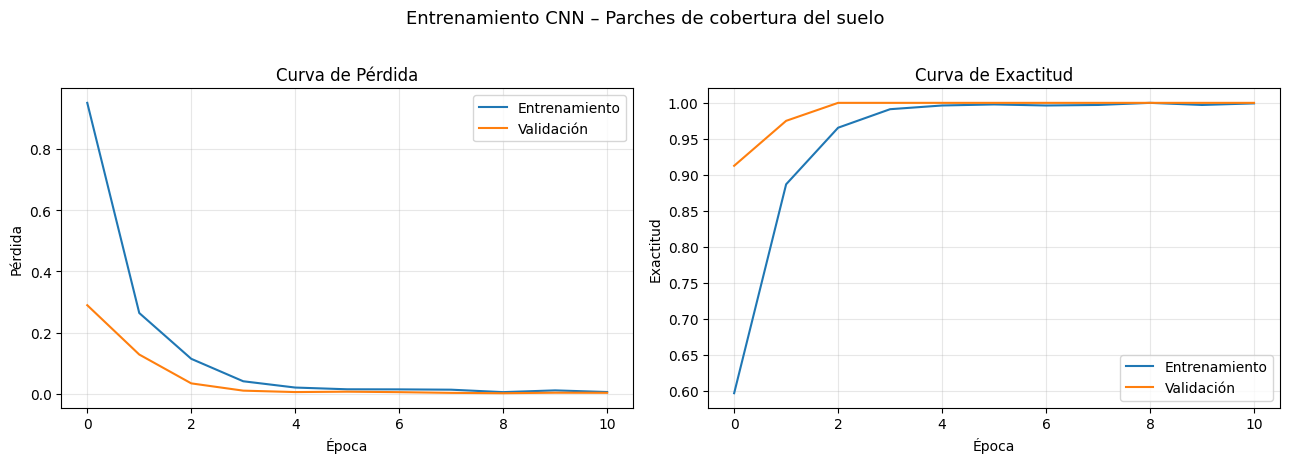

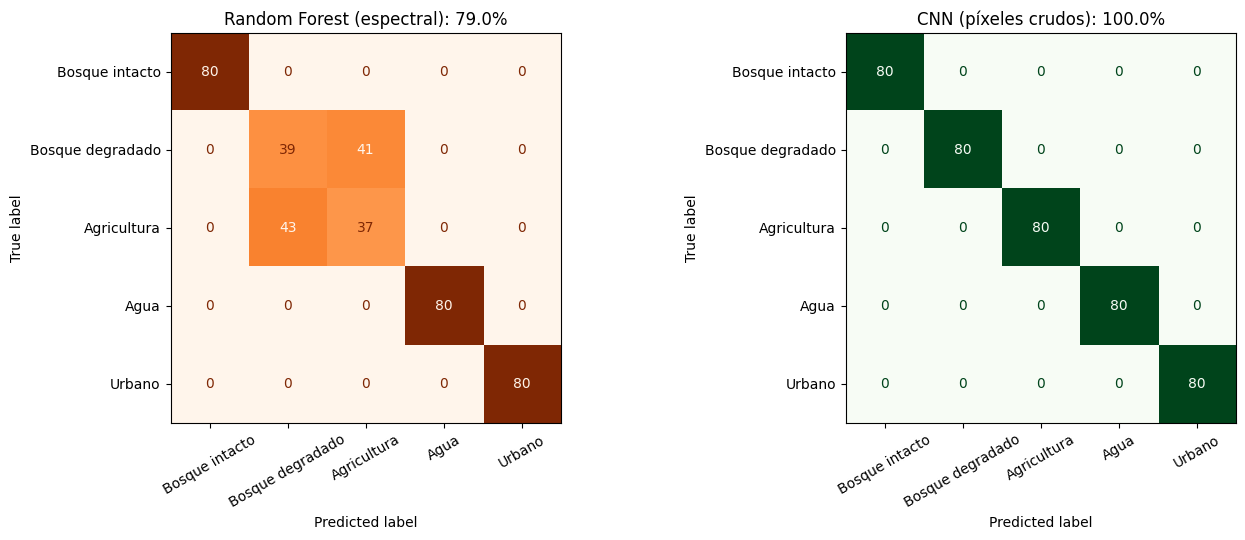

In [ ]:
# Curvas de aprendizaje
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].plot(historial.history['loss'], label='Entrenamiento')
ejes[0].plot(historial.history['val_loss'], label='Validación')
ejes[0].set_xlabel('Época'); ejes[0].set_ylabel('Pérdida'); ejes[0].set_title('Curva de Pérdida')
ejes[1].plot(historial.history['accuracy'], label='Entrenamiento')
ejes[1].plot(historial.history['val_accuracy'], label='Validación')
ejes[1].set_xlabel('Época'); ejes[1].set_ylabel('Exactitud'); ejes[1].set_title('Curva de Exactitud')
for ax in ejes:
    ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Entrenamiento CNN – Parches de cobertura del suelo', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Matrices de confusión: RF vs CNN
pred_cnn = modelo_cnn.predict(X_te, verbose=0).argmax(axis=1)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_te, pred_rf, display_labels=CLASES, ax=ejes[0],
                                        xticks_rotation=30, cmap='Oranges', colorbar=False)
ejes[0].set_title(f'Random Forest (espectral): {exactitud_rf:.1%}')
ConfusionMatrixDisplay.from_predictions(y_te, pred_cnn, display_labels=CLASES, ax=ejes[1],
                                        xticks_rotation=30, cmap='Greens', colorbar=False)
ejes[1].set_title(f'CNN (píxeles crudos): {exactitud_cnn:.1%}')
plt.tight_layout()
plt.show()

## 9. ¿Qué Aprendió la CNN? Mapas de Características

Extraemos la salida de la primera capa convolucional (`conv1`) para un parche agrícola y uno degradado. Cada uno de los 16 filtros **aprendidos** resalta un patrón distinto: bordes en cierta orientación, vegetación, suelo...

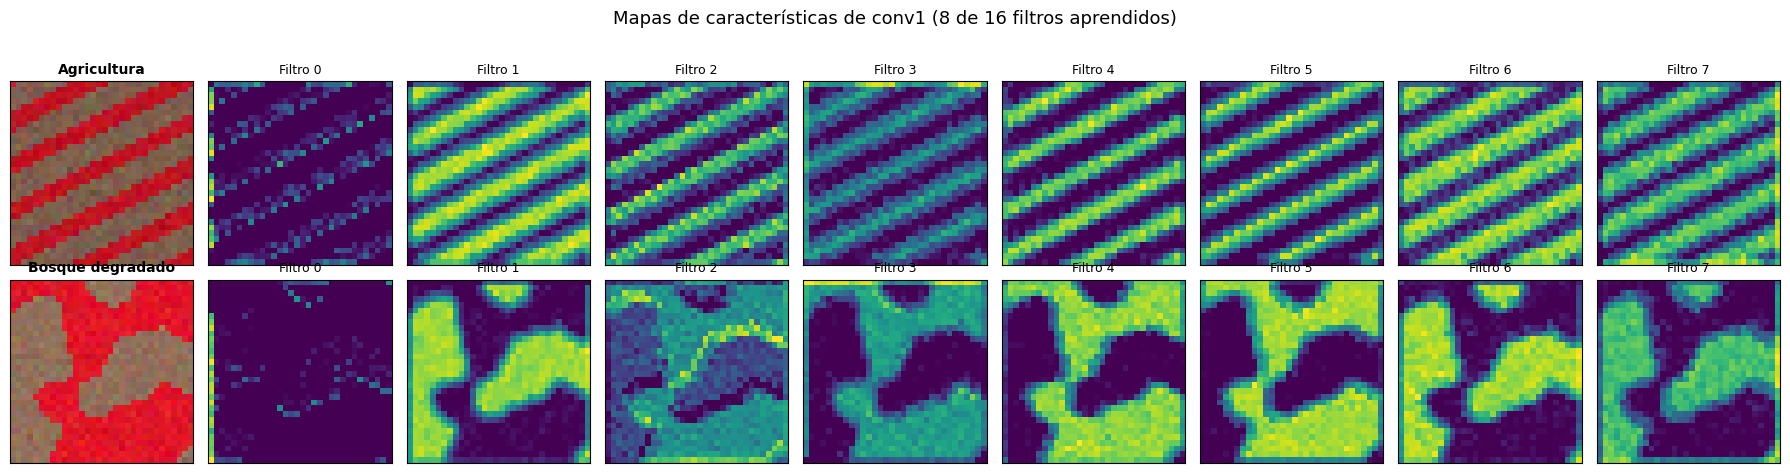

In [ ]:
extractor = keras.Model(inputs=modelo_cnn.inputs,
                        outputs=modelo_cnn.get_layer('conv1').output)

ejemplos = [np.where(y_te == 2)[0][0], np.where(y_te == 1)[0][0]]  # agricultura, degradado
mapas = extractor.predict(X_te[ejemplos], verbose=0)                # (2, 32, 32, 16)

fig, ejes = plt.subplots(2, 9, figsize=(18, 4.6))
for fila, i in enumerate(ejemplos):
    ejes[fila, 0].imshow(falso_color(X_te[i]))
    ejes[fila, 0].set_title(CLASES[y_te[i]], fontweight='bold', fontsize=10)
    for k in range(8):
        ejes[fila, k + 1].imshow(mapas[fila, :, :, k], cmap='viridis')
        ejes[fila, k + 1].set_title(f'Filtro {k}', fontsize=9)
for ax in ejes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Mapas de características de conv1 (8 de 16 filtros aprendidos)', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

## 10. De la Simulación a Datos Reales

La misma arquitectura se aplica a imágenes reales; solo cambia la forma de entrada:

| Datos | Forma del tensor |
|---|---|
| Este lab | `(32, 32, 4)` — B, G, R, NIR |
| Parche Landsat 8/9 | `(64, 64, 6)` — 6 bandas reflectivas |
| Parche Sentinel-2 | `(64, 64, 13)` — 13 bandas |
| [EuroSAT](https://github.com/phelber/EuroSAT) | `(64, 64, 13)` — 27 000 parches etiquetados, 10 clases |

### Flujo de trabajo con datos reales
1. **Exportar parches** desde Google Earth Engine (Lab 6_1) para cada clase (p. ej. con polígonos de MapBiomas Perú o del MINAM)
2. **Preprocesar:** reflectancias a [0, 1]
3. **Dividir:** entrenamiento/validación/prueba **sin solapamiento espacial** (bloques geográficos distintos)
4. **Entrenar CNN** con early stopping y *data augmentation* (rotaciones, volteos)
5. **Evaluar** con datos espacialmente independientes

### (Opcional, en casa) CIFAR-10
La versión anterior de este lab usaba CIFAR-10 (descarga de ~170 MB + entrenamiento de varios minutos). Si quieres probarlo, cambia `EJECUTAR_CIFAR = True` en la siguiente celda; usa solo un subconjunto para que sea rápido.

In [ ]:
EJECUTAR_CIFAR = False   # ⚠️ descarga ~170 MB la primera vez

if EJECUTAR_CIFAR:
    (Xc_tr, yc_tr), (Xc_te, yc_te) = keras.datasets.cifar10.load_data()
    Xc_tr, Xc_te = Xc_tr[:10000] / 255.0, Xc_te[:2000] / 255.0   # subconjunto
    yc_tr, yc_te = yc_tr[:10000].ravel(), yc_te[:2000].ravel()

    modelo_cifar = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu', padding='same'), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dropout(0.5),
        layers.Dense(10, activation='softmax'),
    ])
    modelo_cifar.compile('adam', 'sparse_categorical_crossentropy', metrics=['accuracy'])
    modelo_cifar.fit(Xc_tr, yc_tr, epochs=5, batch_size=64, validation_split=0.1, verbose=2)
    print(f"Exactitud CIFAR-10 (subconjunto): {modelo_cifar.evaluate(Xc_te, yc_te, verbose=0)[1]:.1%}")
else:
    print("CIFAR-10 omitido (EJECUTAR_CIFAR = False)")

CIFAR-10 omitido (EJECUTAR_CIFAR = False)


---
## 🔬 Ejercicio

1. **Quitar la información espacial:** baraja aleatoriamente los píxeles *dentro* de cada parche (la celda siguiente ya trae la función). Las firmas espectrales se conservan, pero el patrón espacial desaparece. Reentrena la CNN: ¿qué exactitud obtiene? ¿Se parece a la del RF? ¿Qué clases confunde?
2. **Arquitectura:** añade un tercer bloque `Conv2D(64) → MaxPooling2D` antes del `Flatten`. ¿Cambia la exactitud? ¿Y el número de parámetros (`summary()`)?
3. ¿Por qué las CNN no necesitan `StandardScaler` aquí, mientras que las ANN densas del Lab 9_1 sí?
4. En el contexto peruano, ¿qué datos de teledetección se beneficiarían más de una CNN que de RF/XGBoost sobre índices tabulares (NDVI, etc.)?

> **Pista:** las CNN brillan cuando la información está en la **disposición espacial** de los píxeles (texturas, formas, bordes), no solo en sus valores.

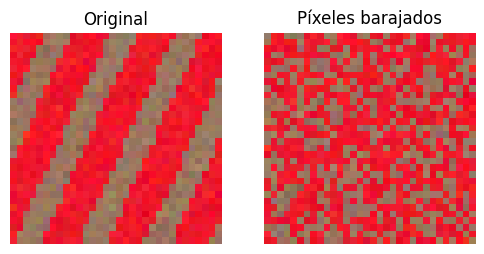

In [ ]:
def barajar_pixeles(X, semilla=0):
    # Permuta los píxeles de cada parche: conserva el espectro, destruye la estructura espacial
    r = np.random.default_rng(semilla)
    n, h, w, b = X.shape
    planos = X.reshape(n, h * w, b).copy()
    for p in planos:
        r.shuffle(p)
    return planos.reshape(n, h, w, b)

X_tr_bar, X_te_bar = barajar_pixeles(X_tr, 1), barajar_pixeles(X_te, 2)

fig, ejes = plt.subplots(1, 2, figsize=(6, 3))
ejes[0].imshow(falso_color(X_tr[y_tr == 2][0])); ejes[0].set_title('Original')
ejes[1].imshow(falso_color(X_tr_bar[y_tr == 2][0])); ejes[1].set_title('Píxeles barajados')
for ax in ejes:
    ax.axis('off')
plt.show()

# Tu código aquí: crea un modelo con la misma arquitectura (keras.models.clone_model),
# compílalo, entrénalo con X_tr_bar y evalúalo con X_te_bar

---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Característica | Una propiedad medible de los datos; las CNN las aprenden automáticamente desde píxeles crudos |
| Tensor | Generalización de escalar/vector/matriz; las imágenes son tensores 3D |
| Aprendizaje de representaciones | Las redes profundas aprenden características automáticamente, sin ingeniería manual |
| Encoder-decoder | Comprimir entrada → representación compacta → producir salida (patrón universal) |
| Convolución | Filtro deslizante detecta patrones locales con pesos compartidos |
| Mapa de características | Salida de una capa convolucional; cada canal codifica un patrón diferente |
| Max Pooling | Reduce dimensiones espaciales; proporciona algo de invarianza a la translación |
| Jerarquía de características | Capas tempranas aprenden bordes; capas profundas aprenden objetos |
| Cuándo usar CNN | Datos de imágenes (parches satelitales, fotos de campo, imágenes de microscopio) |
| No usar CNN cuando | Datos tabulares — preferir RF/XGBoost |

### Aplicaciones CNN en Monitoreo Ambiental Peruano

| Aplicación | Datos de entrada | Salida |
|------------|-----------------|--------|
| Detección de deforestación | Parches Landsat/Sentinel | Bosque / Deforestado / Degradado |
| Clasificación de cobertura | Parches multiespectrales | Tipo de cobertura |
| Conteo de árboles | Imágenes de drone | Número de copas |
| Identificación de especies | Fotos de trampas cámara | Especie de fauna |
| Detección de incendios | Series temporales MODIS | Área quemada |